# Demostración en vivo: predicción a 96 horas

Sistema de Alerta Temprana MINSAL — demanda en urgencias respiratorias.

Este notebook se ejecuta en vivo y usa la muestra versionada en el repositorio.

In [1]:
from pathlib import Path
import json
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Resolver rutas según desde dónde se ejecute el notebook
if Path("../data/sample/sample_predictions.csv").exists():
    SAMPLE = Path("../data/sample/sample_predictions.csv")
    ART = Path("../artifacts")
else:
    SAMPLE = Path("Modelo/data/sample/sample_predictions.csv")
    ART = Path("Modelo/artifacts")

print("Muestra:", SAMPLE)
print("Artefactos:", ART)

Muestra: ../data/sample/sample_predictions.csv
Artefactos: ../artifacts


## 1. Resultados generales de la muestra

Comparamos el total real de atenciones con el total predicho por el modelo.

In [2]:
df = pd.read_csv(SAMPLE)
df["Error_calc"] = (df["Total_real"] - df["Total_predicho"]).abs()

mae = df["Error_calc"].mean()
print(f"Casos en la muestra: {len(df)}")
print(f"MAE de la muestra: {mae:.3f} pacientes")
print(f"Error máximo: {df['Error_calc'].max():.2f} pacientes")
df.head(10)

Casos en la muestra: 200
MAE de la muestra: 0.200 pacientes
Error máximo: 5.00 pacientes


,Fecha,Region,IdEstablecimiento,NEstablecimiento,TipoEstablecimiento,Total_real,Total_predicho,Error_abs,TempMin,MP2_5,Frio_Polar_Flag,Lluvia_Intensa_Flag,Alerta_MP25_Flag,Error_calc
0,2025-11-23,Maule,16-968,SUR El Aromo,SUR,0,0,0.03,11.8,8.58,0,0,0,0
1,2025-12-28,Maule,16-944,SUR Los Niches,SUR,0,0,0.02,15.5,7.15,0,0,0,0
2,2025-12-11,Metropolitana,10-901,SAPU Dr. Alberto Allende Jones,SAPU,3,4,0.80,14.1,17.79,0,0,1,1
3,2025-12-26,O'Higgins,15-949,SUR Paredones,SUR,8,8,0.06,14.0,7.85,0,0,0,0
4,2025-10-03,Metropolitana,13-818,SAPU Paine,SAPU,27,27,0.40,9.8,35.35,0,0,1,0
5,2025-04-14,Atacama,04-101,Hospital Dr. Jerónimo Méndez Arancibia (Chañaral),Hospital,2,2,0.35,13.3,12.47,0,0,0,0
6,2025-09-02,Maule,16-969,SUR Colbun,SUR,50,49,0.90,9.5,10.11,0,0,0,1
7,2025-10-15,Metropolitana,10-933,SUR San Pedro,SUR,10,10,0.02,10.8,24.25,0,0,1,0
8,2025-02-26,Metropolitana,10-932,SUR Isla de Maipo,SUR,1,1,0.08,14.4,26.89,0,0,1,0
9,2025-08-03,Metropolitana,10-908,SAPU Garín,SAPU,0,0,0.07,1.5,70.61,1,0,1,0


## 2. Casos destacados

Elegimos los establecimientos con mayor demanda real para mostrar que el modelo acompaña los picos.

In [3]:
casos = df.nlargest(4, "Total_real")[
    ["NEstablecimiento", "Region", "Fecha", "Total_real", "Total_predicho", "Error_calc"]
]
casos

,NEstablecimiento,Region,Fecha,Total_real,Total_predicho,Error_calc
121,Hospital Regional Dr. Juan Noé Crevani (Arica),Arica y Parinacota,2025-04-08,111,106,5
198,SAPU Esmeralda,Metropolitana,2025-06-09,70,65,5
163,SAPU Juan Pablo II de Antofagasta,Antofagasta,2025-04-01,57,57,0
73,SAPU Los Quillayes,Metropolitana,2025-08-03,54,54,0


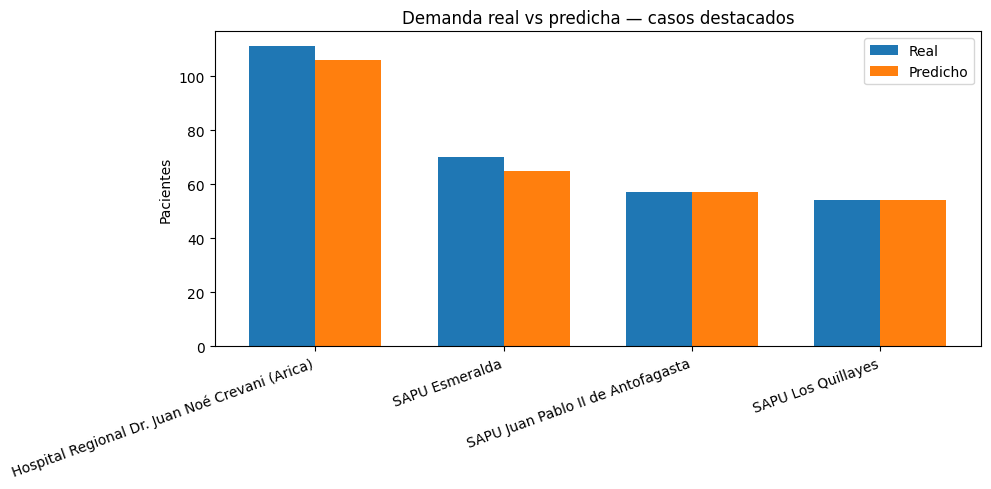

In [4]:
x = np.arange(len(casos))
ancho = 0.35

plt.figure(figsize=(10, 5))
plt.bar(x - ancho / 2, casos["Total_real"], ancho, label="Real")
plt.bar(x + ancho / 2, casos["Total_predicho"], ancho, label="Predicho")
plt.xticks(x, casos["NEstablecimiento"], rotation=20, ha="right")
plt.ylabel("Pacientes")
plt.title("Demanda real vs predicha — casos destacados")
plt.legend()
plt.tight_layout()
plt.show()

## 3. Artefacto del modelo

Verificamos que el modelo versionado carga correctamente desde la carpeta local de artefactos.

In [5]:
meta_path = ART / "model_metadata.json"
feat_path = ART / "features.json"
model_path = ART / "model_rf_respiratorio_v1.joblib"

if meta_path.exists() and feat_path.exists() and model_path.exists():
    with open(meta_path, encoding="utf-8") as f:
        meta = json.load(f)
    with open(feat_path, encoding="utf-8") as f:
        features = json.load(f)
    model = joblib.load(model_path)
    print(f"Modelo: {meta.get('release', 'modelo-v1')}")
    print(f"MAE reportado: {meta['metrics']['MAE']:.3f}")
    print(f"R2 reportado: {meta['metrics']['R2']:.4f}")
    print(f"Features: {len(features)}")
    print(f"Árboles del bosque: {model.n_estimators}")
else:
    print("Los artefactos no están en la carpeta local.")
    print("Descargarlos desde el release modelo-v1 a la carpeta Modelo/artifacts/")

Modelo: modelo-v1
MAE reportado: 0.321
R2 reportado: 0.9956
Features: 20
Árboles del bosque: 200


## Cierre

- El modelo predice la demanda total por establecimiento con un MAE cercano a 0.3 pacientes en la muestra.
- La evidencia versionada está en el release `modelo-v1`.
- Trabajo futuro: predicción por rango etario y API para la aplicación.